# YOLOv3 từ đầu bằng PyTorch cho Road Damage Detection

Notebook này tự xây dựng YOLOv3 cho bài toán phát hiện `Pothole`, `Crack`, `Manhole`.

Mục tiêu:
- Tải và chuẩn hóa Road Damage Dataset theo format YOLO.
- Dùng K-Means để tìm 9 anchor boxes.
- Tự cài Darknet-53 Backbone, FPN Neck và Detection Head YOLOv3.
- Kiểm tra shape output `52x52`, `26x26`, `13x13` với input `416x416`.
- Cài YOLOv3 loss dùng sigmoid + BCE cho objectness và class.
- Có cell train/evaluate/visualize nếu dataset tải được.

## 1. Ý tưởng YOLOv3

YOLOv3 dự đoán ở ba scale:
- `52 x 52`: vật thể nhỏ.
- `26 x 26`: vật thể vừa.
- `13 x 13`: vật thể lớn.

Mỗi ô grid có 3 anchor. Với `C` class, mỗi anchor xuất `5 + C` giá trị:
`tx, ty, tw, th, objectness, class logits`.

In [21]:
# Nếu môi trường đã có đủ package, không cần chạy dòng này.
# Khi nộp bài nên comment lại để tránh notebook tự cài package.
# %pip install -q torch torchvision matplotlib pandas pillow tqdm pyyaml

In [22]:
import math
import random
import shutil
import time
import urllib.error
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import yaml
from IPython.display import display
from PIL import Image, ImageDraw
from torch.utils.data import DataLoader, Dataset
from torchvision.ops import batched_nms, box_iou
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

In [23]:
# =========================================================
# CẤU HÌNH
# =========================================================
IN_COLAB = "COLAB_RELEASE_TAG" in __import__("os").environ
IN_KAGGLE = Path("/kaggle/working").exists()

if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DATA_ROOT = Path("/content/drive/MyDrive/datasets/road_damage_pcm")
    except (ImportError, RuntimeError):
        DATA_ROOT = Path("/content/data/road_damage_pcm")
elif IN_KAGGLE:
    DATA_ROOT = Path("/kaggle/working/datasets/road_damage_pcm")
else:
    DATA_ROOT = Path("./data/road_damage_pcm")

IMAGE_SIZE = 416
BATCH_SIZE = 2
NUM_CLASSES = 3
CLASS_NAMES = ["Pothole", "Crack", "Manhole"]
NUM_EPOCHS = 25
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 5e-4
NUM_WORKERS = 0
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AUTO_DOWNLOAD_DATASET = True

STRIDES = (8, 16, 32)
ANCHORS_PER_SCALE = 3
PREDICTION_SIZE = 5 + NUM_CLASSES
DEFAULT_ANCHORS = torch.tensor([
    [10, 13], [16, 30], [33, 23],
    [30, 61], [62, 45], [59, 119],
    [116, 90], [156, 198], [373, 326],
], dtype=torch.float32)

assert IMAGE_SIZE % 32 == 0, "IMAGE_SIZE phải chia hết cho 32."

In [24]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)
print(f"Device: {DEVICE}")
print(f"Data root: {DATA_ROOT.resolve() if not IN_COLAB and not IN_KAGGLE else DATA_ROOT}")

Device: cuda
Data root: D:\DuyToan\Python\DUT_AI\day 51 13-8-2026\yolov3\data\road_damage_pcm


## 2. Tải và chuẩn hóa dataset

Dataset gốc có ảnh và label YOLO. Cell dưới tải file zip, chia train/valid theo tỷ lệ 80/20 và đưa về cấu trúc:

```text
data/road_damage_pcm/
  train/images, train/labels
  valid/images, valid/labels
```

In [25]:
# =========================================================
# TẢI VÀ CHUẨN HÓA ROAD DAMAGE DATASET
# =========================================================
DATASET_URL = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes"
)
DATASET_ARCHIVE = DATA_ROOT.parent / "road_damage_pcm.zip"


def download_file(url, destination):
    request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=120) as response, destination.open("wb") as file:
        shutil.copyfileobj(response, file)


def prepare_road_damage_dataset(data_root=DATA_ROOT):
    ready_file = data_root / ".ready"
    if ready_file.exists():
        print(f"Dataset đã sẵn sàng tại: {data_root}")
        return

    DATASET_ARCHIVE.parent.mkdir(parents=True, exist_ok=True)
    if not DATASET_ARCHIVE.exists() or not zipfile.is_zipfile(DATASET_ARCHIVE):
        print("Đang tải Road Damage Dataset khoảng 195 MB...")
        download_file(DATASET_URL, DATASET_ARCHIVE)

    image_prefix = "data/images/"
    label_prefix = "data/labels-YOLO/"
    image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

    with zipfile.ZipFile(DATASET_ARCHIVE) as archive:
        names = archive.namelist()
        labels = set(name for name in names if name.startswith(label_prefix))
        pairs = []
        for image_name in names:
            if not image_name.startswith(image_prefix) or Path(image_name).suffix.lower() not in image_exts:
                continue
            label_name = f"{label_prefix}{Path(image_name).stem}.txt"
            if label_name in labels:
                pairs.append((image_name, label_name))

        random.Random(SEED).shuffle(pairs)
        split_index = int(0.8 * len(pairs))
        for index, (image_name, label_name) in enumerate(tqdm(pairs, desc="Chuẩn hóa dataset")):
            split = "train" if index < split_index else "valid"
            for member, folder in ((image_name, "images"), (label_name, "labels")):
                destination = data_root / split / folder / Path(member).name
                destination.parent.mkdir(parents=True, exist_ok=True)
                with archive.open(member) as source, destination.open("wb") as target:
                    shutil.copyfileobj(source, target)

    data_yaml = {
        "path": str(data_root.resolve()),
        "train": "train/images",
        "val": "valid/images",
        "names": CLASS_NAMES,
    }
    with (data_root / "data.yaml").open("w", encoding="utf-8") as file:
        yaml.safe_dump(data_yaml, file, sort_keys=False, allow_unicode=True)
    ready_file.write_text(str(len(pairs)), encoding="utf-8")
    print(f"Hoàn tất: {split_index} train | {len(pairs) - split_index} validation")


if AUTO_DOWNLOAD_DATASET:
    try:
        prepare_road_damage_dataset()
    except (OSError, urllib.error.URLError, zipfile.BadZipFile) as error:
        print("Không thể tải dataset:", error)
        print("Các cell shape test và loss test vẫn chạy được bằng dữ liệu giả.")

Dataset đã sẵn sàng tại: data\road_damage_pcm


In [26]:
# =========================================================
# DATASET VÀ DATALOADER
# =========================================================
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


class YOLODetectionDataset(Dataset):
    def __init__(self, data_root, split, image_size):
        self.image_dir = Path(data_root) / split / "images"
        self.label_dir = Path(data_root) / split / "labels"
        self.image_size = image_size
        if not self.image_dir.exists():
            raise FileNotFoundError(f"Không tìm thấy {self.image_dir}.")
        self.image_paths = sorted(
            path for path in self.image_dir.iterdir()
            if path.suffix.lower() in IMAGE_EXTENSIONS
        )

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]
        image = Image.open(image_path).convert("RGB")
        image = TF.to_tensor(TF.resize(image, [self.image_size, self.image_size], antialias=True))

        labels, boxes = [], []
        label_path = self.label_dir / f"{image_path.stem}.txt"
        if label_path.exists():
            for line in label_path.read_text(encoding="utf-8").splitlines():
                if not line.strip():
                    continue
                class_id, x, y, width, height = line.split()
                labels.append(int(class_id))
                boxes.append([float(x), float(y), float(width), float(height)])

        return image, {
            "labels": torch.tensor(labels, dtype=torch.long),
            "boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
        }


def detection_collate_fn(batch):
    images, targets = zip(*batch)
    return torch.stack(images), list(targets)


def build_dataloaders():
    train_dataset = YOLODetectionDataset(DATA_ROOT, "train", IMAGE_SIZE)
    val_dataset = YOLODetectionDataset(DATA_ROOT, "valid", IMAGE_SIZE)
    options = dict(
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        collate_fn=detection_collate_fn,
    )
    train_loader = DataLoader(train_dataset, shuffle=True, **options)
    val_loader = DataLoader(val_dataset, shuffle=False, **options)
    return train_dataset, val_dataset, train_loader, val_loader


try:
    train_dataset, val_dataset, train_loader, val_loader = build_dataloaders()
    DATA_AVAILABLE = True
    print(f"Train: {len(train_dataset)} | Validation: {len(val_dataset)}")
except FileNotFoundError as error:
    DATA_AVAILABLE = False
    train_dataset = val_dataset = train_loader = val_loader = None
    print(error)
    print("Bỏ qua train/evaluate nếu dataset chưa sẵn sàng.")

Train: 1607 | Validation: 402


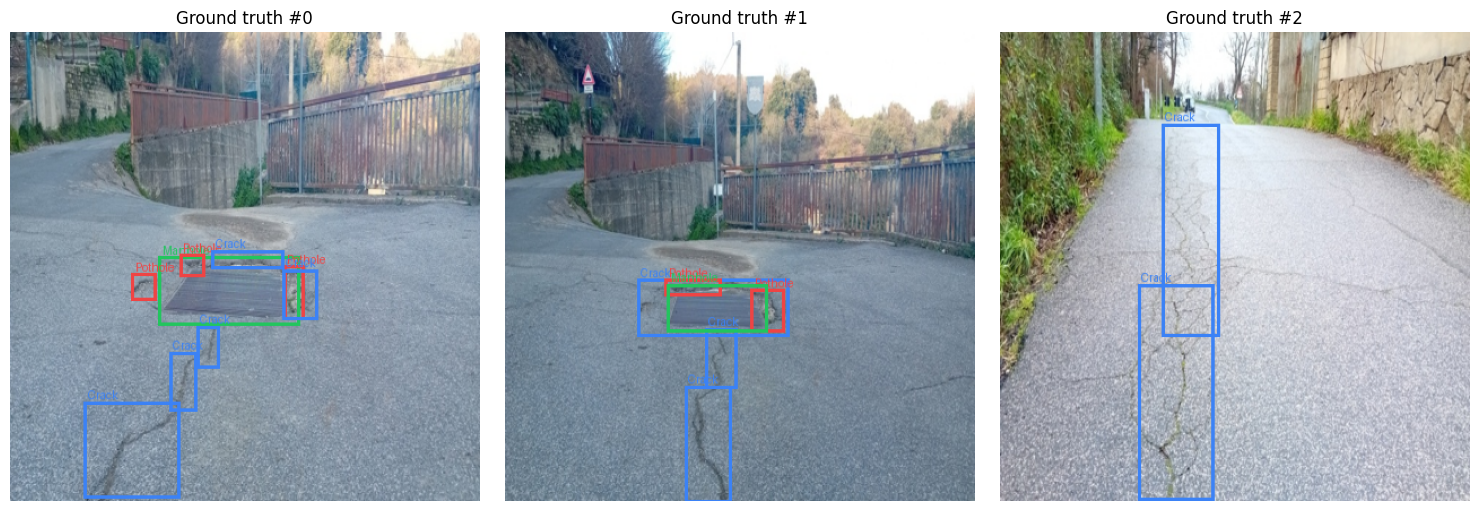

In [27]:
# =========================================================
# VISUALIZE DATASET
# =========================================================
BOX_COLORS = ["#ef4444", "#3b82f6", "#22c55e", "#f59e0b", "#a855f7"]


def xywhn_to_xyxy(boxes, image_size):
    if boxes.numel() == 0:
        return boxes.reshape(0, 4)
    x, y, w, h = boxes.unbind(-1)
    return torch.stack([
        (x - w / 2) * image_size,
        (y - h / 2) * image_size,
        (x + w / 2) * image_size,
        (y + h / 2) * image_size,
    ], dim=-1)


def draw_boxes(image, boxes, labels, scores=None, class_names=CLASS_NAMES):
    canvas = TF.to_pil_image(image.cpu().clamp(0, 1))
    draw = ImageDraw.Draw(canvas)
    for index, (box, label) in enumerate(zip(boxes, labels)):
        color = BOX_COLORS[int(label) % len(BOX_COLORS)]
        x1, y1, x2, y2 = [float(value) for value in box]
        draw.rectangle((x1, y1, x2, y2), outline=color, width=3)
        text = class_names[int(label)]
        if scores is not None:
            text += f" {float(scores[index]):.2f}"
        draw.text((x1 + 3, max(0, y1 - 12)), text, fill=color)
    return canvas


def show_dataset_samples(dataset, count=3):
    count = min(count, len(dataset))
    fig, axes = plt.subplots(1, count, figsize=(5 * count, 5), squeeze=False)
    for index in range(count):
        image, target = dataset[index]
        boxes = xywhn_to_xyxy(target["boxes"], image.shape[-1])
        axes[0, index].imshow(draw_boxes(image, boxes, target["labels"]))
        axes[0, index].set_title(f"Ground truth #{index}")
        axes[0, index].axis("off")
    plt.tight_layout()
    display(fig)
    plt.close(fig)


if DATA_AVAILABLE:
    show_dataset_samples(train_dataset)
else:
    print("Bỏ qua visualization vì dataset chưa tồn tại.")

## 3. K-Means Anchor Boxes

YOLOv3 là anchor-based. Ta gom `width, height` của ground-truth box, nhân với `IMAGE_SIZE`, rồi dùng K-Means để tìm 9 anchor.

Khoảng cách dùng là `1 - IoU(width, height)`.

In [28]:
# =========================================================
# K-MEANS ANCHOR BOXES
# =========================================================
def wh_iou(box_wh, cluster_wh):
    box_wh = box_wh[:, None, :]
    cluster_wh = cluster_wh[None, :, :]
    intersection = torch.minimum(box_wh, cluster_wh).prod(dim=-1)
    union = box_wh.prod(dim=-1) + cluster_wh.prod(dim=-1) - intersection
    return intersection / (union + 1e-9)


def collect_box_wh(dataset):
    all_wh = []
    for image_path in tqdm(dataset.image_paths, desc="Đọc label để cluster anchor"):
        label_path = dataset.label_dir / f"{image_path.stem}.txt"
        if not label_path.exists():
            continue
        for line in label_path.read_text(encoding="utf-8").splitlines():
            if not line.strip():
                continue
            _, _, _, width, height = line.split()
            all_wh.append([float(width) * IMAGE_SIZE, float(height) * IMAGE_SIZE])
    if not all_wh:
        return torch.empty(0, 2)
    return torch.tensor(all_wh, dtype=torch.float32).clamp(min=1.0)


def kmeans_anchors(box_wh, k=9, iterations=50, seed=SEED):
    if box_wh.shape[0] < k:
        return DEFAULT_ANCHORS.clone()

    generator = torch.Generator().manual_seed(seed)
    indices = torch.randperm(box_wh.shape[0], generator=generator)[:k]
    clusters = box_wh[indices].clone()

    for _ in range(iterations):
        distances = 1 - wh_iou(box_wh, clusters)
        assignments = distances.argmin(dim=1)
        new_clusters = clusters.clone()
        for cluster_index in range(k):
            members = box_wh[assignments == cluster_index]
            if len(members) > 0:
                new_clusters[cluster_index] = members.median(dim=0).values
        if torch.allclose(clusters, new_clusters):
            break
        clusters = new_clusters

    areas = clusters.prod(dim=1)
    return clusters[areas.argsort()]


if DATA_AVAILABLE:
    box_wh = collect_box_wh(train_dataset)
    ANCHORS = kmeans_anchors(box_wh)
    mean_iou = wh_iou(box_wh, ANCHORS).max(dim=1).values.mean().item()
    print("K-Means anchors:")
    print(ANCHORS.round().int())
    print(f"Mean best IoU: {mean_iou:.3f}")
else:
    ANCHORS = DEFAULT_ANCHORS.clone()
    print("Dùng default YOLOv3 anchors vì dataset chưa có:")
    print(ANCHORS.int())

ANCHORS_BY_SCALE = ANCHORS.view(3, 3, 2)
print("Anchors theo scale 52/26/13:")
print(ANCHORS_BY_SCALE.round().int())

Đọc label để cluster anchor: 100%|██████████| 1607/1607 [00:00<00:00, 8909.68it/s]


K-Means anchors:
tensor([[ 17,  14],
        [ 27,  18],
        [ 37,  21],
        [ 25,  32],
        [ 44,  28],
        [ 36,  58],
        [ 60,  39],
        [ 75,  73],
        [150, 110]], dtype=torch.int32)
Mean best IoU: 0.728
Anchors theo scale 52/26/13:
tensor([[[ 17,  14],
         [ 27,  18],
         [ 37,  21]],

        [[ 25,  32],
         [ 44,  28],
         [ 36,  58]],

        [[ 60,  39],
         [ 75,  73],
         [150, 110]]], dtype=torch.int32)


## 4. Backbone Darknet-53

Darknet-53 dùng residual block:

`x -> Conv 1x1 -> Conv 3x3 -> + x`

Backbone trả về:
- stride 8: `52 x 52`
- stride 16: `26 x 26`
- stride 32: `13 x 13`

In [29]:
# =========================================================
# YOLOV3 BUILDING BLOCKS
# =========================================================
class ConvBNLeaky(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=1, stride=1):
        super().__init__()
        padding = kernel_size // 2
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(0.1, inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        hidden_channels = channels // 2
        self.conv1 = ConvBNLeaky(channels, hidden_channels, kernel_size=1)
        self.conv2 = ConvBNLeaky(hidden_channels, channels, kernel_size=3)

    def forward(self, x):
        return x + self.conv2(self.conv1(x))


def make_residual_stage(in_channels, out_channels, repeats):
    layers = [ConvBNLeaky(in_channels, out_channels, kernel_size=3, stride=2)]
    layers += [ResidualBlock(out_channels) for _ in range(repeats)]
    return nn.Sequential(*layers)

In [30]:
# =========================================================
# BACKBONE: DARKNET-53
# =========================================================
class Darknet53Backbone(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = ConvBNLeaky(3, 32, kernel_size=3, stride=1)
        self.stage1 = make_residual_stage(32, 64, repeats=1)
        self.stage2 = make_residual_stage(64, 128, repeats=2)
        self.stage3 = make_residual_stage(128, 256, repeats=8)
        self.stage4 = make_residual_stage(256, 512, repeats=8)
        self.stage5 = make_residual_stage(512, 1024, repeats=4)
        self.out_channels = (256, 512, 1024)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        small = self.stage3(x)
        medium = self.stage4(small)
        large = self.stage5(medium)
        return small, medium, large

## 5. Neck FPN và Detection Head

Neck dùng top-down FPN:

`13x13 -> upsample -> concat 26x26 -> upsample -> concat 52x52`

Detection Head xuất:

`(Batch, 3 * (5 + Num_Classes), S, S)`

Với 3 class, mỗi scale có `3 * (5 + 3) = 24` channel.

In [31]:
# =========================================================
# NECK: FPN TOP-DOWN
# =========================================================
class YOLOv3ConvSet(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            ConvBNLeaky(in_channels, out_channels, kernel_size=1),
            ConvBNLeaky(out_channels, out_channels * 2, kernel_size=3),
            ConvBNLeaky(out_channels * 2, out_channels, kernel_size=1),
            ConvBNLeaky(out_channels, out_channels * 2, kernel_size=3),
            ConvBNLeaky(out_channels * 2, out_channels, kernel_size=1),
        )

    def forward(self, x):
        return self.block(x)


class YOLOv3Neck(nn.Module):
    def __init__(self, channels=(256, 512, 1024)):
        super().__init__()
        c_small, c_medium, c_large = channels
        self.large_set = YOLOv3ConvSet(c_large, 512)
        self.large_route = ConvBNLeaky(512, 256, kernel_size=1)
        self.medium_set = YOLOv3ConvSet(256 + c_medium, 256)
        self.medium_route = ConvBNLeaky(256, 128, kernel_size=1)
        self.small_set = YOLOv3ConvSet(128 + c_small, 128)
        self.upsample = nn.Upsample(scale_factor=2, mode="nearest")
        self.out_channels = (128, 256, 512)

    def forward(self, features):
        small, medium, large = features
        large_feature = self.large_set(large)
        medium_input = torch.cat([self.upsample(self.large_route(large_feature)), medium], dim=1)
        medium_feature = self.medium_set(medium_input)
        small_input = torch.cat([self.upsample(self.medium_route(medium_feature)), small], dim=1)
        small_feature = self.small_set(small_input)
        return small_feature, medium_feature, large_feature

In [32]:
# =========================================================
# DETECTION HEAD
# =========================================================
class YOLOv3DetectionHead(nn.Module):
    def __init__(self, channels, num_classes):
        super().__init__()
        self.num_classes = num_classes
        self.out_channels = ANCHORS_PER_SCALE * (5 + num_classes)
        self.heads = nn.ModuleList()
        for channel in channels:
            self.heads.append(nn.Sequential(
                ConvBNLeaky(channel, channel * 2, kernel_size=3),
                nn.Conv2d(channel * 2, self.out_channels, kernel_size=1),
            ))

    def forward(self, features):
        return [head(feature) for head, feature in zip(self.heads, features)]


class YOLOv3(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.backbone = Darknet53Backbone()
        self.neck = YOLOv3Neck(self.backbone.out_channels)
        self.head = YOLOv3DetectionHead(self.neck.out_channels, num_classes)

    def forward(self, x):
        features = self.backbone(x)
        features = self.neck(features)
        return self.head(features)

In [33]:
# =========================================================
# SHAPE TEST
# =========================================================
set_seed(SEED)
model = YOLOv3(NUM_CLASSES)
x = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE)

model.eval()
with torch.no_grad():
    backbone_features = model.backbone(x)
    neck_features = model.neck(backbone_features)
    outputs = model.head(neck_features)

expected_hw = [IMAGE_SIZE // stride for stride in STRIDES]
expected_backbone_channels = model.backbone.out_channels
expected_neck_channels = model.neck.out_channels
expected_output_channels = ANCHORS_PER_SCALE * (5 + NUM_CLASSES)

for index, (bf, nf, out, hw, bc, nc) in enumerate(
    zip(backbone_features, neck_features, outputs, expected_hw, expected_backbone_channels, expected_neck_channels),
    start=1,
):
    assert bf.shape == (2, bc, hw, hw), f"Backbone scale {index} sai shape: {bf.shape}"
    assert nf.shape == (2, nc, hw, hw), f"Neck scale {index} sai shape: {nf.shape}"
    assert out.shape == (2, expected_output_channels, hw, hw), f"Head scale {index} sai shape: {out.shape}"
    print(f"Scale {index}: backbone={tuple(bf.shape)} | neck={tuple(nf.shape)} | pred={tuple(out.shape)}")

full_outputs = model(x)
assert len(full_outputs) == 3, "YOLOv3 phải trả về 3 scale."
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f"Full forward: OK | Parameters: {parameter_count / 1e6:.2f}M")

Scale 1: backbone=(2, 256, 52, 52) | neck=(2, 128, 52, 52) | pred=(2, 24, 52, 52)
Scale 2: backbone=(2, 512, 26, 26) | neck=(2, 256, 26, 26) | pred=(2, 24, 26, 26)
Scale 3: backbone=(2, 1024, 13, 13) | neck=(2, 512, 13, 13) | pred=(2, 24, 13, 13)
Full forward: OK | Parameters: 61.53M


## 6. YOLOv3 Loss

Loss gồm:
- Box center `x, y`: BCE sau sigmoid trong cell grid.
- Box size `w, h`: học `log(gt_wh / anchor_wh)`.
- Objectness: BCE cho toàn bộ grid/anchor.
- Class: BCE cho từng class độc lập, không dùng Softmax.

Đây là bản học tập, giữ đơn giản để dễ hiểu. Bản production thường có thêm ignore mask, augmentation mạnh và nhiều trick training.

In [34]:
# =========================================================
# TARGET ASSIGNMENT CHO YOLOV3
# =========================================================
def reshape_predictions(output, num_classes=NUM_CLASSES):
    batch_size, _, grid_h, grid_w = output.shape
    output = output.view(batch_size, ANCHORS_PER_SCALE, 5 + num_classes, grid_h, grid_w)
    return output.permute(0, 1, 3, 4, 2).contiguous()


def xywh_to_xyxy(boxes):
    center, size = boxes[..., :2], boxes[..., 2:]
    return torch.cat([center - size / 2, center + size / 2], dim=-1)


def build_yolov3_targets(outputs, targets, anchors_by_scale, image_size=IMAGE_SIZE, num_classes=NUM_CLASSES):
    device = outputs[0].device
    all_anchors = anchors_by_scale.reshape(-1, 2).to(device)
    scale_targets = []

    for output in outputs:
        batch_size, _, grid_h, grid_w = output.shape
        target = torch.zeros(
            batch_size, ANCHORS_PER_SCALE, grid_h, grid_w, 5 + num_classes,
            device=device,
        )
        scale_targets.append(target)

    for batch_index, target in enumerate(targets):
        labels = target["labels"].to(device)
        boxes = target["boxes"].to(device)
        if labels.numel() == 0:
            continue

        box_wh_pixels = boxes[:, 2:4] * image_size
        best_anchor = wh_iou(box_wh_pixels.cpu(), all_anchors.cpu()).argmax(dim=1).to(device)

        for object_index, anchor_index in enumerate(best_anchor):
            scale_index = int(anchor_index // ANCHORS_PER_SCALE)
            anchor_in_scale = int(anchor_index % ANCHORS_PER_SCALE)
            grid_size = scale_targets[scale_index].shape[2]

            cx, cy, bw, bh = boxes[object_index]
            grid_x = torch.clamp((cx * grid_size).long(), 0, grid_size - 1)
            grid_y = torch.clamp((cy * grid_size).long(), 0, grid_size - 1)
            if scale_targets[scale_index][batch_index, anchor_in_scale, grid_y, grid_x, 4] == 1:
                continue

            anchor_wh = all_anchors[anchor_index]
            scale_targets[scale_index][batch_index, anchor_in_scale, grid_y, grid_x, 0] = cx * grid_size - grid_x.float()
            scale_targets[scale_index][batch_index, anchor_in_scale, grid_y, grid_x, 1] = cy * grid_size - grid_y.float()
            scale_targets[scale_index][batch_index, anchor_in_scale, grid_y, grid_x, 2] = torch.log(bw * image_size / anchor_wh[0] + 1e-9)
            scale_targets[scale_index][batch_index, anchor_in_scale, grid_y, grid_x, 3] = torch.log(bh * image_size / anchor_wh[1] + 1e-9)
            scale_targets[scale_index][batch_index, anchor_in_scale, grid_y, grid_x, 4] = 1.0
            scale_targets[scale_index][batch_index, anchor_in_scale, grid_y, grid_x, 5 + labels[object_index]] = 1.0

    return scale_targets

In [35]:
# =========================================================
# YOLOV3 LOSS
# =========================================================
class YOLOv3Loss:
    def __init__(self, anchors_by_scale, num_classes=NUM_CLASSES):
        self.anchors_by_scale = anchors_by_scale.float()
        self.num_classes = num_classes
        self.bce = nn.BCEWithLogitsLoss(reduction="sum")
        self.mse = nn.MSELoss(reduction="sum")

    def __call__(self, outputs, targets, image_size=IMAGE_SIZE):
        target_maps = build_yolov3_targets(
            outputs, targets, self.anchors_by_scale, image_size, self.num_classes
        )
        total_xy = total_wh = total_obj = total_cls = 0.0
        positive_count = 0.0

        for output, target in zip(outputs, target_maps):
            pred = reshape_predictions(output, self.num_classes)
            obj_mask = target[..., 4] == 1
            noobj_mask = ~obj_mask
            positive_count += obj_mask.sum().float()

            total_obj = total_obj + self.bce(pred[..., 4][obj_mask], target[..., 4][obj_mask])
            total_obj = total_obj + 0.5 * self.bce(pred[..., 4][noobj_mask], target[..., 4][noobj_mask])

            if obj_mask.any():
                total_xy = total_xy + self.bce(pred[..., 0:2][obj_mask], target[..., 0:2][obj_mask])
                total_wh = total_wh + self.mse(pred[..., 2:4][obj_mask], target[..., 2:4][obj_mask])
                total_cls = total_cls + self.bce(pred[..., 5:][obj_mask], target[..., 5:][obj_mask])
            else:
                total_xy = total_xy + output.sum() * 0.0
                total_wh = total_wh + output.sum() * 0.0
                total_cls = total_cls + output.sum() * 0.0

        normalizer = positive_count.clamp(min=1.0)
        box_loss = (total_xy + total_wh) / normalizer
        obj_loss = total_obj / normalizer
        cls_loss = total_cls / normalizer
        loss = box_loss + obj_loss + cls_loss
        parts = {
            "loss": loss.detach(),
            "box_loss": box_loss.detach(),
            "obj_loss": obj_loss.detach(),
            "cls_loss": cls_loss.detach(),
            "positive": positive_count.detach(),
        }
        return loss, parts

In [36]:
# =========================================================
# LOSS + BACKWARD SMOKE TEST
# =========================================================
set_seed(SEED)
smoke_model = YOLOv3(NUM_CLASSES).to(DEVICE).train()
smoke_images = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
smoke_targets = [
    {"labels": torch.tensor([0]), "boxes": torch.tensor([[0.50, 0.50, 0.35, 0.30]])},
    {"labels": torch.tensor([1]), "boxes": torch.tensor([[0.35, 0.40, 0.25, 0.20]])},
]
smoke_outputs = smoke_model(smoke_images)
smoke_criterion = YOLOv3Loss(ANCHORS_BY_SCALE, NUM_CLASSES)
smoke_loss, smoke_parts = smoke_criterion(smoke_outputs, smoke_targets, image_size=IMAGE_SIZE)
assert torch.isfinite(smoke_loss), f"Loss không hữu hạn: {smoke_loss}"
assert smoke_parts["positive"].item() > 0, "Target assignment chưa tạo positive anchor."
smoke_loss.backward()
has_gradient = any(
    parameter.grad is not None and torch.isfinite(parameter.grad).all()
    for parameter in smoke_model.parameters()
)
assert has_gradient, "Backward chưa tạo gradient hữu hạn."
print({key: float(value) for key, value in smoke_parts.items()})
print("Loss + backward: OK")
del smoke_model, smoke_images, smoke_outputs
if torch.cuda.is_available():
    torch.cuda.empty_cache()

{'loss': 3843.990234375, 'box_loss': 2.25256609916687, 'obj_loss': 3839.554443359375, 'cls_loss': 2.1831846237182617, 'positive': 2.0}
Loss + backward: OK


## 7. Training Loop

Phần này chỉ chạy nếu dataset đã tải thành công. Nếu bạn chỉ cần kiểm tra kiến trúc, các cell shape test và loss test ở trên là đủ.

In [37]:
def move_targets_to_device(targets, device):
    return [{key: value.to(device) for key, value in target.items()} for target in targets]


def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)
    totals = {"loss": 0.0, "box_loss": 0.0, "obj_loss": 0.0, "cls_loss": 0.0}
    total_items = 0
    context = torch.enable_grad() if is_training else torch.no_grad()

    with context:
        for images, targets in tqdm(loader, leave=False):
            images = images.to(DEVICE, non_blocking=True)
            targets = move_targets_to_device(targets, DEVICE)
            if is_training:
                optimizer.zero_grad(set_to_none=True)

            outputs = model(images)
            loss, parts = criterion(outputs, targets, image_size=images.shape[-1])
            if is_training:
                loss.backward()
                optimizer.step()

            batch_size = images.shape[0]
            total_items += batch_size
            for key in totals:
                totals[key] += float(parts[key]) * batch_size

    return {key: value / max(total_items, 1) for key, value in totals.items()}


def train_model(model, train_loader, val_loader, num_epochs=NUM_EPOCHS):
    model = model.to(DEVICE)
    criterion = YOLOv3Loss(ANCHORS_BY_SCALE, NUM_CLASSES)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    history = []

    for epoch in range(1, num_epochs + 1):
        start = time.time()
        train_stats = run_epoch(model, train_loader, criterion, optimizer)
        val_stats = run_epoch(model, val_loader, criterion)
        row = {"epoch": epoch}
        row.update({f"train_{key}": value for key, value in train_stats.items()})
        row.update({f"val_{key}": value for key, value in val_stats.items()})
        history.append(row)
        print(
            f"Epoch {epoch:02d}/{num_epochs} | "
            f"train {train_stats['loss']:.4f} | val {val_stats['loss']:.4f} | "
            f"box {val_stats['box_loss']:.4f} | obj {val_stats['obj_loss']:.4f} | "
            f"cls {val_stats['cls_loss']:.4f} | {time.time() - start:.1f}s"
        )
    return model, pd.DataFrame(history)


def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["epoch"], history["train_loss"], marker="o", label="train")
    axes[0].plot(history["epoch"], history["val_loss"], marker="s", label="validation")
    for name in ("box_loss", "obj_loss", "cls_loss"):
        axes[1].plot(history["epoch"], history[f"val_{name}"], marker="o", label=name)
    axes[0].set(title="Total loss", xlabel="Epoch", ylabel="Loss")
    axes[1].set(title="Validation loss components", xlabel="Epoch", ylabel="Loss")
    for axis in axes:
        axis.grid(alpha=0.3)
        axis.legend()
    plt.tight_layout()
    display(fig)
    plt.close(fig)

Epoch 01/25 | train 40.8411 | val 11.3080 | box 2.1234 | obj 7.6968 | cls 1.4877 | 104.2s


Epoch 02/25 | train 10.6818 | val 10.3605 | box 1.7899 | obj 7.1118 | cls 1.4587 | 103.7s


Epoch 03/25 | train 11.0529 | val 10.3763 | box 1.6398 | obj 7.2915 | cls 1.4450 | 101.2s


Epoch 04/25 | train 11.5574 | val 13.8250 | box 4.5210 | obj 7.7299 | cls 1.5742 | 111.5s


Epoch 05/25 | train 10.7341 | val 10.3330 | box 1.6354 | obj 7.2537 | cls 1.4439 | 97.5s


...

Epoch 22/25 | train 9.5934 | val 9.5190 | box 1.5246 | obj 6.6597 | cls 1.3347 | 106.9s


Epoch 23/25 | train 9.3734 | val 9.5583 | box 1.5128 | obj 6.6845 | cls 1.3610 | 113.6s


Epoch 24/25 | train 9.0478 | val 9.1595 | box 1.5101 | obj 6.3112 | cls 1.3382 | 109.6s


Epoch 25/25 | train 8.8854 | val 8.9635 | box 1.5096 | obj 6.1349 | cls 1.3190 | 108.3s


,epoch,train_loss,train_box_loss,train_obj_loss,train_cls_loss,val_loss,val_box_loss,val_obj_loss,val_cls_loss
0,1,40.8411,2.2942,36.9709,1.5759,11.3080,2.1234,7.6968,1.4877
1,2,10.6818,1.7798,7.4427,1.4592,10.3605,1.7899,7.1118,1.4587
2,3,11.0529,2.1529,7.4091,1.4909,10.3763,1.6398,7.2915,1.4450
3,4,11.5574,2.4647,7.5882,1.5045,13.8250,4.5210,7.7299,1.5742
4,5,10.7341,1.9621,7.3336,1.4384,10.3330,1.6354,7.2537,1.4439
5,6,10.1188,1.7036,7.0084,1.4068,10.1297,1.7967,6.9118,1.4212
6,7,9.9478,1.6435,6.9006,1.4038,9.7311,1.5767,6.7499,1.4045
7,8,9.9833,1.7131,6.8886,1.3816,9.7066,1.5638,6.7439,1.3989
8,9,9.8677,1.6782,6.7922,1.3972,9.6113,1.5596,6.6818,1.3700
9,10,9.8249,1.6551,6.8116,1.3582,10.0110,1.7060,6.9272,1.3778


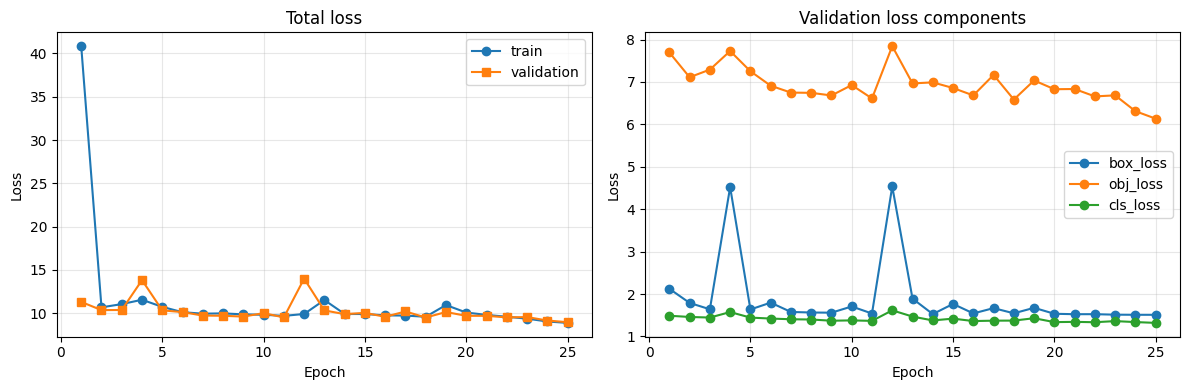

In [38]:
if DATA_AVAILABLE:
    set_seed(SEED)
    model = YOLOv3(NUM_CLASSES)
    model, history = train_model(model, train_loader, val_loader, NUM_EPOCHS)
    display(history.style.format(precision=4))
    plot_history(history)
else:
    print("Bỏ qua train vì dataset chưa sẵn sàng. Model và loss đã qua smoke test.")

## 8. Inference và NMS

YOLOv3 decode output bằng công thức:
- `bx = (sigmoid(tx) + cx) * stride`
- `by = (sigmoid(ty) + cy) * stride`
- `bw = anchor_w * exp(tw)`
- `bh = anchor_h * exp(th)`

Confidence cuối cùng = `objectness * class_probability`.

In [39]:
# =========================================================
# DECODE OUTPUT + NMS
# =========================================================
def decode_yolov3_outputs(outputs, anchors_by_scale, image_size=IMAGE_SIZE, num_classes=NUM_CLASSES):
    all_boxes, all_scores, all_labels = [], [], []
    device = outputs[0].device
    anchors_by_scale = anchors_by_scale.to(device)

    for scale_index, output in enumerate(outputs):
        pred = reshape_predictions(output, num_classes)
        batch_size, _, grid_h, grid_w, _ = pred.shape
        stride = image_size / grid_h
        anchors = anchors_by_scale[scale_index].view(1, ANCHORS_PER_SCALE, 1, 1, 2)

        y, x = torch.meshgrid(
            torch.arange(grid_h, device=device, dtype=pred.dtype),
            torch.arange(grid_w, device=device, dtype=pred.dtype),
            indexing="ij",
        )
        grid = torch.stack([x, y], dim=-1).view(1, 1, grid_h, grid_w, 2)

        center = (pred[..., 0:2].sigmoid() + grid) * stride
        size = anchors * pred[..., 2:4].exp()
        boxes = torch.cat([center - size / 2, center + size / 2], dim=-1)
        objectness = pred[..., 4].sigmoid()
        class_prob = pred[..., 5:].sigmoid()
        class_scores, labels = class_prob.max(dim=-1)
        scores = objectness * class_scores

        all_boxes.append(boxes.reshape(batch_size, -1, 4))
        all_scores.append(scores.reshape(batch_size, -1))
        all_labels.append(labels.reshape(batch_size, -1))

    return torch.cat(all_boxes, dim=1), torch.cat(all_scores, dim=1), torch.cat(all_labels, dim=1)


@torch.no_grad()
def postprocess(outputs, confidence_threshold=0.25, iou_threshold=0.5, max_detections=100):
    boxes, scores, labels = decode_yolov3_outputs(outputs, ANCHORS_BY_SCALE, IMAGE_SIZE, NUM_CLASSES)
    results = []
    for image_boxes, image_scores, image_labels in zip(boxes, scores, labels):
        keep = image_scores >= confidence_threshold
        image_boxes = image_boxes[keep]
        image_scores = image_scores[keep]
        image_labels = image_labels[keep]
        if image_boxes.numel() == 0:
            results.append({"boxes": image_boxes.reshape(0, 4), "scores": image_scores, "labels": image_labels})
            continue
        keep_indices = batched_nms(image_boxes, image_scores, image_labels, iou_threshold)
        keep_indices = keep_indices[:max_detections]
        results.append({
            "boxes": image_boxes[keep_indices],
            "scores": image_scores[keep_indices],
            "labels": image_labels[keep_indices],
        })
    return results


@torch.no_grad()
def predict_batch(model, images, confidence_threshold=0.25, iou_threshold=0.5):
    model.eval()
    outputs = model(images.to(DEVICE))
    return postprocess(outputs, confidence_threshold, iou_threshold)

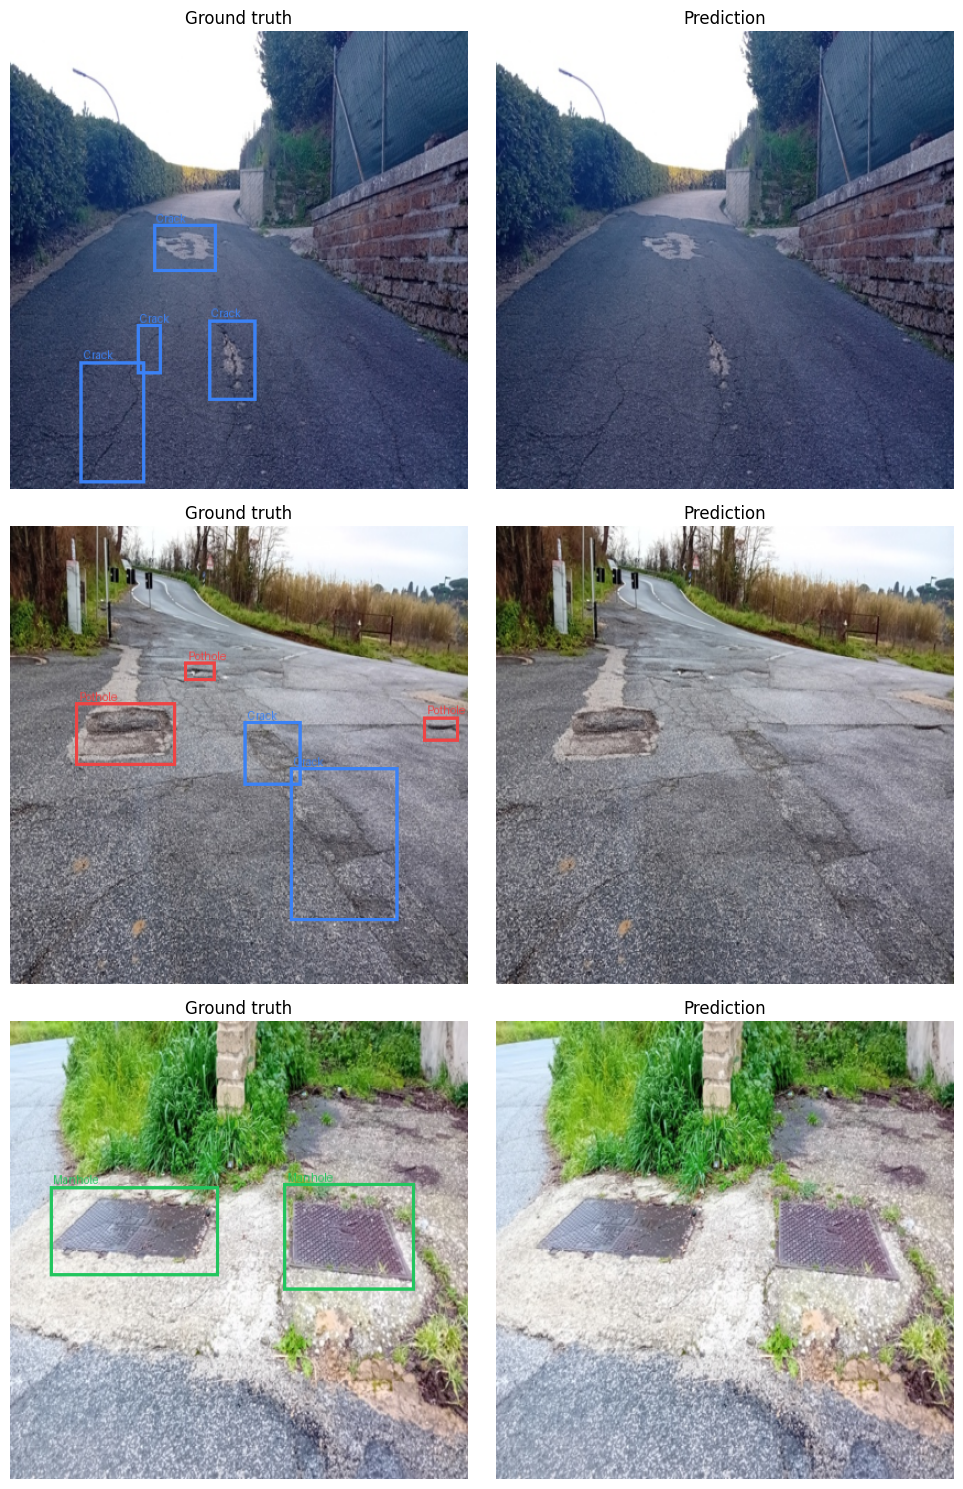

In [40]:
def show_predictions(model, dataset, count=3, confidence_threshold=0.25):
    count = min(count, len(dataset))
    images, targets = [], []
    for index in range(count):
        image, target = dataset[index]
        images.append(image)
        targets.append(target)
    batch = torch.stack(images)
    predictions = predict_batch(model, batch, confidence_threshold=confidence_threshold)

    fig, axes = plt.subplots(count, 2, figsize=(10, 5 * count), squeeze=False)
    for index in range(count):
        gt_boxes = xywhn_to_xyxy(targets[index]["boxes"], IMAGE_SIZE)
        axes[index, 0].imshow(draw_boxes(images[index], gt_boxes, targets[index]["labels"]))
        axes[index, 0].set_title("Ground truth")
        axes[index, 0].axis("off")

        pred = predictions[index]
        axes[index, 1].imshow(draw_boxes(images[index], pred["boxes"].cpu(), pred["labels"].cpu(), pred["scores"].cpu()))
        axes[index, 1].set_title("Prediction")
        axes[index, 1].axis("off")
    plt.tight_layout()
    display(fig)
    plt.close(fig)


if DATA_AVAILABLE and "model" in globals():
    show_predictions(model, val_dataset, count=3, confidence_threshold=0.25)
else:
    print("Bỏ qua prediction visualization vì chưa train hoặc chưa có dataset.")

## 9. Nhận xét cuối bài

**FPN trong Neck giúp gì cho vật thể nhỏ?**

Feature sâu như `13x13` có ngữ nghĩa mạnh nhưng spatial resolution thấp, nên khó định vị vật nhỏ. FPN upsample feature sâu rồi concatenate với feature nông `26x26` và `52x52`. Nhờ vậy scale `52x52` vừa giữ chi tiết vị trí tốt, vừa nhận thêm thông tin ngữ nghĩa từ tầng sâu.

**Vì sao YOLOv3 dùng Independent Logistic Classifiers thay vì Softmax?**

Softmax ép tổng xác suất các class bằng 1, nghĩa là các class loại trừ nhau hoàn toàn. YOLOv3 dùng sigmoid riêng cho từng class và BCE cho từng class, nên mỗi class được học như một bài toán đúng/sai độc lập.

**Khác biệt chính với YOLOv8:**

YOLOv3 là anchor-based: mỗi prediction gắn với anchor box cố định, nên cần K-Means anchor. YOLOv8 là anchor-free: dự đoán khoảng cách từ grid point đến bốn cạnh box, không cần anchor box cố định.